In [ ]:
# Install the project dependencies.
%pip install -q -r ../../requirements.txt


In [10]:
import sys
import shutil
from pathlib import Path

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


RUN = ROOT / "reproduction/weights/2026-04-17_10-18-24_MC_100reps"

# Figure 10 is the quadratic (Burke) data-generating process, as the caption in
# 6_Simulations.tex says.
SPEC = "Burke"

OUT = ROOT / "paper/Figures/MonteCarlo/FE_Recovery"

# The estimated tables store 1-based period indices, not years.
FIRST_YEAR = 1960

plt.style.use("ggplot")
plt.rcParams["font.size"] = 12
RED, BLUE = "#E24A33", "#348ABD"




In [11]:
def load_table(path):
    # 100 replications x N columns, wide.
    t = pd.read_csv(path)
    return t.loc[:, ~t.columns.str.contains("^Unnamed")]


true_country = np.load(RUN / f"country_effect_relative{SPEC}.npy",
                       allow_pickle=True).item()
true_time = np.load(RUN / f"time_trend_relative{SPEC}.npy",
                    allow_pickle=True).item()

country_table = load_table(RUN / f"country_FE_table_{SPEC}.csv")
time_table = load_table(RUN / f"time_FE_table_{SPEC}.csv")

print(f"country FE: {country_table.shape[0]} reps x {country_table.shape[1]} countries")
print(f"time FE:    {time_table.shape[0]} reps x {time_table.shape[1]} periods")


country FE: 100 reps x 195 countries
time FE:    100 reps x 62 periods


In [12]:
# Align on the ISO code, so a country missing from either side is dropped
# rather than silently paired with the wrong one.
countries = [c for c in country_table.columns if c in true_country]

c_mean = country_table[countries].mean(axis=0)
c_true = pd.Series({c: true_country[c] for c in countries})

print(f"{len(countries)} countries matched")
print(f"corr(mean estimate, true)  {np.corrcoef(c_mean, c_true)[0, 1]:.4f}")
print(f"mean |bias|                {(c_mean - c_true).abs().mean():.4f}")


195 countries matched
corr(mean estimate, true)  0.9799
mean |bias|                0.0056


In [13]:
# Columns are period indices, mapped to years before matching the true dict.
period = np.array([int(col) for col in time_table.columns])
year = FIRST_YEAR + period
keep = np.array([y in true_time for y in year])
cols = [col for col, k in zip(time_table.columns, keep) if k]
year = year[keep]

t_mean = time_table[cols].mean(axis=0).values
t_lo = time_table[cols].quantile(0.025, axis=0).values
t_hi = time_table[cols].quantile(0.975, axis=0).values
t_true = np.array([true_time[y] for y in year])

print(f"{len(year)} years matched, {year.min()} to {year.max()}")
print(f"corr(mean estimate, true)  {np.corrcoef(t_mean, t_true)[0, 1]:.4f}")
print(f"mean |bias|                {np.abs(t_mean - t_true).mean():.4f}")
print(f"mean width of the 95% band {np.mean(t_hi - t_lo):.4f}")


62 years matched, 1962 to 2023
corr(mean estimate, true)  1.0000
mean |bias|                0.0006
mean width of the 95% band 0.0079


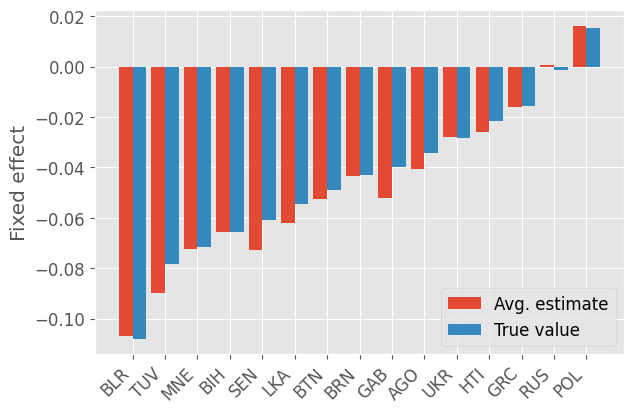

In [14]:
# 15 countries spread evenly over the range of the true fixed effect, so the
# panel is not dominated by one part of the distribution.
order = sorted(countries, key=lambda c: c_true[c])
idx = np.linspace(0, len(order) - 1, 15, dtype=int)
selected = [order[i] for i in idx]

x = np.arange(len(selected))
width = 0.42

fig_c, ax = plt.subplots(figsize=(6.5, 4.3))
ax.bar(x - width / 2, c_mean[selected].values, width=width,
       color=RED, label="Avg. estimate")
ax.bar(x + width / 2, c_true[selected].values, width=width,
       color=BLUE, label="True value")

ax.set_ylabel("Fixed effect")
ax.set_xticks(x)
ax.set_xticklabels(selected, rotation=45, ha="right")
ax.legend(loc="lower right")

fig_c.tight_layout()
plt.show()


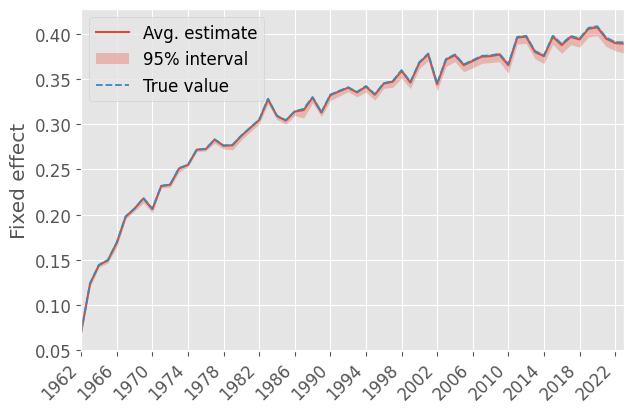

In [15]:
fig_t, ax = plt.subplots(figsize=(6.5, 4.3))
ax.plot(year, t_mean, color=RED, lw=1.5, label="Avg. estimate")
ax.fill_between(year, t_lo, t_hi, color=RED, alpha=0.3, lw=0,
                label="95% interval")
ax.plot(year, t_true, color=BLUE, lw=1.3, ls="--", label="True value")

ax.set_ylabel("Fixed effect")
ax.set_xlim(year.min(), year.max())
ax.set_xticks(year[::4])
ax.set_xticklabels(year[::4], rotation=45, ha="right")
ax.legend(loc="upper left")

fig_t.tight_layout()
plt.show()
